# 03 - YOLOv8 Dataset Preparation

In this notebook, we prepare the brain MRI dataset for YOLOv8 tumor detection:
1. Locate all raw images and bounding box annotation files (.txt).
2. Match image-label pairs and verify label contents.
3. Split into Train (70%), Valid (15%), and Test (15%).
4. Organize files into the standard YOLO directory structure (`images/` and `labels/`).
5. Create `data.yaml` for YOLOv8 training.
6. Visualize sample images with their ground truth bounding boxes.


In [1]:
from pathlib import Path
import shutil
import random
import json
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# 1. Setup paths
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
YOLO_DIR = ROOT / "data" / "prepared" / "detection"
REPORT_DIR = ROOT / "outputs" / "reports"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Raw data directory:    {RAW_DIR}")
print(f"YOLO output directory: {YOLO_DIR}")


Raw data directory:    C:\Users\hamza\Desktop\dev_ai\NeuroVision\data\raw
YOLO output directory: C:\Users\hamza\Desktop\dev_ai\NeuroVision\data\prepared\detection


In [2]:
# 2. Match images and label files
image_files = {}
label_files = {}

for split in ["Train", "Val"]:
    for cls_name in ["Glioma", "Meningioma", "No Tumor", "Pituitary"]:
        img_folder = RAW_DIR / split / cls_name / "images"
        lbl_folder = RAW_DIR / split / cls_name / "labels"
        
        if img_folder.exists():
            for f in img_folder.glob("*.jpg"):
                image_files[f.stem] = f
                
        if lbl_folder.exists():
            for f in lbl_folder.glob("*.txt"):
                label_files[f.stem] = f

matched_stems = sorted(list(set(image_files.keys()) & set(label_files.keys())))

print(f"Total images found: {len(image_files)}")
print(f"Total labels found: {len(label_files)}")
print(f"Matched pairs:      {len(matched_stems)}")


Total images found: 5249


Total labels found: 5249
Matched pairs:      5247


In [3]:
# 3. Split into Train (70%), Valid (15%), Test (15%)
random.seed(42)
shuffled_stems = matched_stems.copy()
random.shuffle(shuffled_stems)

total_pairs = len(shuffled_stems)
n_train = int(0.70 * total_pairs)
n_valid = int(0.15 * total_pairs)

train_stems = shuffled_stems[:n_train]
valid_stems = shuffled_stems[n_train:n_train + n_valid]
test_stems = shuffled_stems[n_train + n_valid:]

print(f"Train split: {len(train_stems)} pairs (70%)")
print(f"Valid split: {len(valid_stems)} pairs (15%)")
print(f"Test split:  {len(test_stems)} pairs (15%)")


Train split: 3672 pairs (70%)
Valid split: 787 pairs (15%)
Test split:  788 pairs (15%)


In [4]:
# 4. Copy images and save normalized YOLO labels
if YOLO_DIR.exists():
    shutil.rmtree(YOLO_DIR)

splits = {
    "train": train_stems,
    "valid": valid_stems,
    "test": test_stems
}

for split_name, stems in splits.items():
    img_dest = YOLO_DIR / "images" / split_name
    lbl_dest = YOLO_DIR / "labels" / split_name
    img_dest.mkdir(parents=True, exist_ok=True)
    lbl_dest.mkdir(parents=True, exist_ok=True)
    
    for stem in stems:
        # Copy image
        src_img = image_files[stem]
        shutil.copy2(src_img, img_dest / src_img.name)
        
        # Save label: keep normalized bbox coordinates with class_id = 0 (tumor)
        src_lbl = label_files[stem]
        content = src_lbl.read_text(encoding="utf-8", errors="ignore").strip()
        
        out_lines = []
        if content:
            for line in content.splitlines():
                parts = line.strip().split()
                if len(parts) == 5:
                    out_lines.append(f"0 {parts[1]} {parts[2]} {parts[3]} {parts[4]}")
        
        (lbl_dest / f"{stem}.txt").write_text("\n".join(out_lines), encoding="utf-8")

print("All images and labels copied to YOLO layout successfully!")


All images and labels copied to YOLO layout successfully!


In [5]:
# 5. Create data.yaml config for YOLOv8
yaml_content = f"""# YOLOv8 Brain Tumor Detection Dataset
path: {YOLO_DIR.resolve().as_posix()}
train: images/train
val: images/valid
test: images/test

nc: 1
names: ['tumor']
"""

yaml_path = YOLO_DIR / "data.yaml"
yaml_path.write_text(yaml_content, encoding="utf-8")
print(f"Saved data.yaml to {yaml_path}")
print("\n--- data.yaml ---")
print(yaml_content.strip())


Saved data.yaml to C:\Users\hamza\Desktop\dev_ai\NeuroVision\data\prepared\detection\data.yaml

--- data.yaml ---
# YOLOv8 Brain Tumor Detection Dataset
path: C:/Users/hamza/Desktop/dev_ai/NeuroVision/data/prepared/detection
train: images/train
val: images/valid
test: images/test

nc: 1
names: ['tumor']


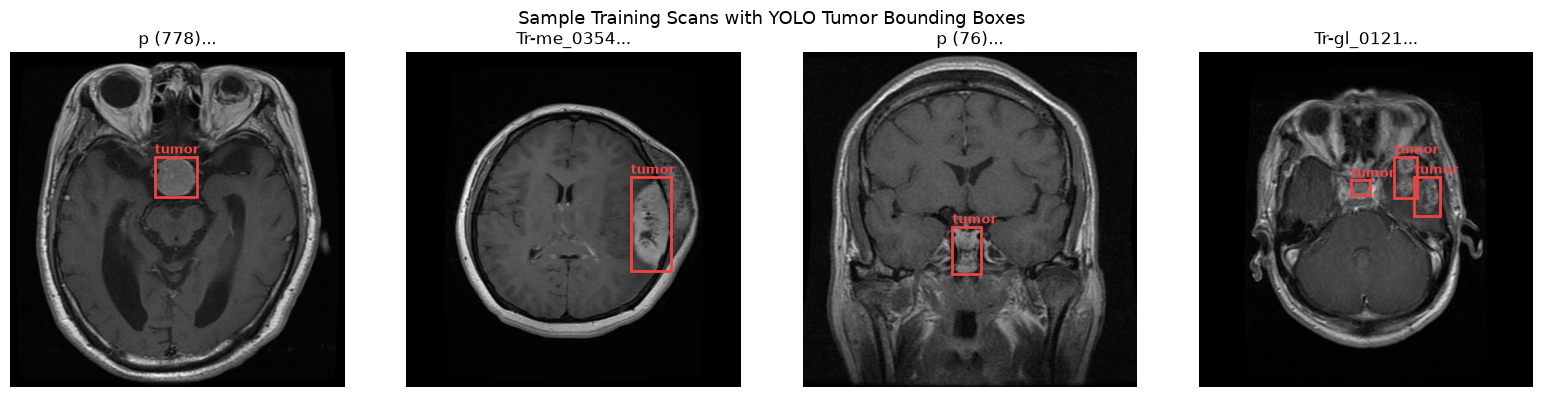

In [6]:
# 6. Visual inspection: sample images with bounding boxes
sample_stems = [s for s in train_stems if (YOLO_DIR / "labels" / "train" / f"{s}.txt").read_text().strip()][:4]

fig, axes = plt.subplots(1, len(sample_stems), figsize=(16, 4))

for idx, stem in enumerate(sample_stems):
    img_path = YOLO_DIR / "images" / "train" / f"{stem}.jpg"
    lbl_path = YOLO_DIR / "labels" / "train" / f"{stem}.txt"
    
    img = Image.open(img_path).convert("RGB")
    w_img, h_img = img.size
    
    axes[idx].imshow(img)
    
    for line in lbl_path.read_text().strip().splitlines():
        parts = line.split()
        if len(parts) == 5:
            _, cx, cy, bw, bh = map(float, parts)
            x1 = (cx - bw / 2) * w_img
            y1 = (cy - bh / 2) * h_img
            rect = patches.Rectangle((x1, y1), bw * w_img, bh * h_img,
                                     linewidth=2, edgecolor="#EF4444", facecolor="none")
            axes[idx].add_patch(rect)
            axes[idx].text(x1, max(y1 - 5, 12), "tumor", color="#EF4444", fontsize=9, weight="bold")
            
    axes[idx].set_title(f"{stem[:15]}...")
    axes[idx].axis("off")

plt.suptitle("Sample Training Scans with YOLO Tumor Bounding Boxes", fontsize=13)
plt.tight_layout()
plt.savefig(REPORT_DIR / "yolo_sample_boxes.png", dpi=100)
plt.show()


In [7]:
# 7. Save summary report
report = {
    "total_images": len(image_files),
    "total_labels": len(label_files),
    "matched_pairs": len(matched_stems),
    "valid_pairs": len(matched_stems),
    "splits": {
        "train": {"images": len(train_stems), "labels": len(train_stems)},
        "valid": {"images": len(valid_stems), "labels": len(valid_stems)},
        "test": {"images": len(test_stems), "labels": len(test_stems)}
    },
    "classes": ["tumor"],
    "data_yaml": str(yaml_path)
}

report_file = REPORT_DIR / "yolo_quality_report.json"
with open(report_file, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

print(f"Quality report saved: {report_file}")
print(json.dumps(report, indent=2))


Quality report saved: C:\Users\hamza\Desktop\dev_ai\NeuroVision\outputs\reports\yolo_quality_report.json
{
  "total_images": 5249,
  "total_labels": 5249,
  "matched_pairs": 5247,
  "valid_pairs": 5247,
  "splits": {
    "train": {
      "images": 3672,
      "labels": 3672
    },
    "valid": {
      "images": 787,
      "labels": 787
    },
    "test": {
      "images": 788,
      "labels": 788
    }
  },
  "classes": [
    "tumor"
  ],
  "data_yaml": "C:\\Users\\hamza\\Desktop\\dev_ai\\NeuroVision\\data\\prepared\\detection\\data.yaml"
}
